<a href="https://colab.research.google.com/github/zhilyaevaviktorija/machine_learning/blob/main/DL_homeworks/Homework_2_hugging_face_transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**Hugging Face Transformers**

###**Часть 1. Самостоятельный разбор туториалов Hugging Face**

**Материал 1. Text classification task guide**

*1. Что делает данный компонент/функция?*

Этот материал показывает полный путь обучения модели DistilBERT для классификации текста: загрузка данных -> подготовка текста -> обучение и проверка результата. Главная задача - научить модель отличать хороший отзыв от плохого.

*2. Какие параметры критичны для классификации текста и почему?*

* `num_labels=2` и словари `id2label`/`label2id` - они говорят модели, что классов два и как они называются;
* при токенизации важен `truncation=True` - длинные отзывы нужно обрезать до допустимой длины модели;
* `learning_rate`, `batch_size`, число эпох и `DataCollatorWithPadding` - они влияют на скорость и качество обучения.

*3. Один пример кода из туториала, который вы планируете использовать.*

Этот пример показывает, как загрузить готовую предобученную модель DistilBERT и настроить ее под задачу классификации текста на два класса.

```
model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased",
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)
```

**Материал 2. Trainer documentation**

*1. Что делает данный компонент/функция?*

Trainer помогает в обучении моделей. Для этого мы даем ему модель, данные и настройки, а он сам выполняет всю работу: запускает обучение (`train()`), проверяет качество (`evaluate()`), делает предсказания (`predict()`) и может загрузить готовую модель на Hugging Face (`push_to_hub()`). Это удобно, чтобы не писать вручную циклы для расчета ошибки и обновления весов.

*2. Какие параметры критичны для классификации текста и почему?*

* `model` - модель (например, DistilBERT), которая будет учиться;
* `args` (`TrainingArguments`) задает скорость обучения (`learning_rate`), количество эпох и размер батча. Без них обучение либо не запустится, либо будет неэффективным;
*  `train_dataset` и `eval_dataset`* - данные для обучения и проверки;
* `processing_class` (токенизатор) нужен, чтобы `Trainer` знал, как правильно обрабатывать текст и делать паддинг;
* `compute_metrics` - функция для подсчета `accuracy` или `F1-score`. Без нее Trainer будет показывать только `loss`, а для классификации важно видеть реальное качество (например, сколько отзывов модель угадала).

*3. Один пример кода из туториала, который вы планируете использовать.*

Этот пример показывает, как создать `TrainingArguments` и изменить размеры батчей с помощью вспомогательного метода `set_dataloader()`.

```
from transformers import TrainingArguments

args = TrainingArguments("working_dir")
args = args.set_dataloader(train_batch_size=16, eval_batch_size=64)
args.per_device_train_batch_size
```

**Материал 3. Datasets: load local CSV/JSON**

*1. Что делает данный компонент/функция?*

`load_dataset()` - это универсальная функция загрузки данных. Она приводит данные из разных источников к единому формату датасета, с которым потом удобно работать: смотреть примеры, делить на train/test, передавать в модель. Для данных, которые хранятся в памяти, есть отдельные методы: `Dataset.from_dict()`, `Dataset.from_list()`, `Dataset.from_pandas()`.

*2. Какие параметры критичны для классификации текста и почему?*

Для классификации текста при загрузке критичны:

* `data_files` указывает, какие файлы брать и как их разложить по сплитам (`train`, `test`, `validation`). Без этого можно случайно загрузить все в один сплит или не те файлы;
* `split` позволяет взять только нужную часть (например, `"train"` или `"train[10:20]"`), чтобы не грузить лишнее;
* `features` с `ClassLabel` задает человекочитаемые названия классов (например, `["sadness", "joy", ...]`). Это важно, потому что иначе метки будут просто числами, и модель/метрики будет сложнее интерпретировать;
* Для CSV еще важны `column_names` и `delimiter`, чтобы правильно разобрать колонки с текстом и меткой.

*3. Один пример кода из туториала, который вы планируете использовать.*

Этот пример показывает, как загрузить CSV-файл с текстом и метками через `load_dataset()` и задать понятные названия классов для задачи классификации текста.

```
class_names = ["sadness", "joy", "love", "anger", "fear", "surprise"]
emotion_features = Features({'text': Value('string'), 'label': ClassLabel(names=class_names)})

dataset = load_dataset(
    'csv',
    data_files=file_dict,
    delimiter=';',
    column_names=['text', 'label'],
    features=emotion_features
)
```

**Материал 4. Evaluate: F1 metric**

*1. Что делает данный компонент/функция?*

Помогает найти лидерборд под задачу, прочитать карточку модели и понять, как посчитать метрики через библиотеки. `Evaluate` дает готовые метрики, а `LightEval` предназначен для оценки больших языковых моделей.

*2. Какие параметры критичны для классификации текста и почему?*

Для оценки классификации критичны: выбранная метрика (`accuracy`, `F1` и т.п.), тестовый датасет и правильные `predictions`/`references`. Это важно, потому что на несбалансированных классах `accuracy` может вводить в заблуждение, и тогда лучше смотреть `F1`.

* `micro` считает общую F1 по всем объектам. В задаче с одним правильным классом совпадает с `accuracy`;
* `macro` считает F1 по каждому классу отдельно и берет простое среднее. Все классы равны, даже редкие;
* `weighted` - тоже среднее по классам, но с весом по количеству примеров. Частые классы влияют сильнее.

*3. Один пример кода из туториала, который вы планируете использовать.*

В данном материале нет примеров кода, но можно использовать этот пример с библиотекой `Evaluate`:
```
import evaluate

accuracy = evaluate.load("accuracy")
accuracy.compute(predictions=[0, 1, 1], references=[0, 1, 0])
```

Этот пример показывает, как загрузить метрику `accuracy` и посчитать ее на маленьком примере.

**Проверка понимания**

1. Чем `problem_type="single_label_classification"` отличается от `"multi_label_classification"` с точки зрения функции потерь?

Разница в функции потерь, которую модель выбирает сама.
* `single_label_classification` -> `CrossEntropyLoss`: правильный только один класс (отзыв либо хороший, либо плохой);
* `multi_label_classification` -> `BCEWithLogitsLoss`: верных классов может быть несколько сразу (текст и грустный, и злой).

2. Зачем нужен `processing_class=tok` в `Trainer` (а не `tokenizer=tok`)?

`processing_class` - более общий параметр. Он подходит не только для токенизатора, но и для обработчика картинок и т.п.

3. Что произойдёт, если не передать `compute_metrics` в `Trainer`?
`Trainer` будет показывать только `eval_loss`, а `accuracy`, `F1` и другие метрики считать не будет. Он не знает, какие метрики нам нужны.

###**Часть 2. Выбор темы и обучение классификатора**
Анализ тональности отзывов

In [ ]:
# Устанавливаем библиотеки
%pip install -q transformers datasets evaluate accelerate scikit-learn

In [ ]:
# Импортируем библиотеки
import numpy as np
import evaluate
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [ ]:
# Загружаем и подготавливаем данные
print("Загрузка данных...")
dataset = load_dataset("stanfordnlp/imdb")
tokenizer = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")

def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, max_length=128)

tokenized_datasets = dataset.map(tokenize_function, batched=True)

# Берем подвыборку для ускорения обучения
small_train = tokenized_datasets["train"].shuffle(seed=42).select(range(600))
small_eval = tokenized_datasets["test"].shuffle(seed=42).select(range(150))

Загрузка данных...


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (8 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [ ]:
# Вычисляем метрики accuracy и f1_macro
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    accuracy = accuracy_metric.compute(predictions=predictions, references=labels)["accuracy"]
    f1_macro = f1_metric.compute(predictions=predictions, references=labels, average="macro")["f1"]
    return {"accuracy": accuracy, "f1_macro": f1_macro}

In [ ]:
# Настраиваем модель и аргументы обучения
id2label = {0: "NEGATIVE", 1: "POSITIVE"}
label2id = {"NEGATIVE": 0, "POSITIVE": 1}

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased",
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

training_args = TrainingArguments(
    output_dir="./imdb-sentiment-model",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    logging_steps=50,
    report_to="none",
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
# Создаем Trainer с early stopping
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=small_train,
    eval_dataset=small_eval,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

In [ ]:
# Обучаем модель
print("Начало обучения...")
trainer.train()

Начало обучения...


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,0.644787,0.753333,0.752000
2,0.661609,0.509103,0.746667,0.744440
3,0.449588,0.444965,0.820000,0.819928


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=114, training_loss=0.5323449143192225, metrics={'train_runtime': 51.2816, 'train_samples_per_second': 35.1, 'train_steps_per_second': 2.223, 'total_flos': 59610329395200.0, 'train_loss': 0.5323449143192225, 'epoch': 3.0})


Финальная оценка модели:


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.449588,0.444965,3,0.820000,0.819928


{'eval_loss': 0.44496479630470276, 'eval_accuracy': 0.82, 'eval_f1_macro': 0.8199279711884754}

Построение confusion matrix...


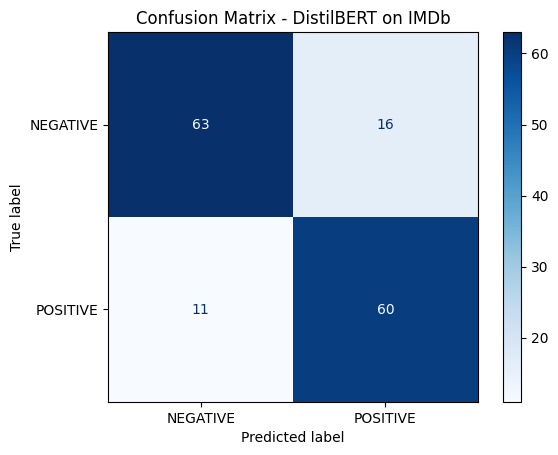

In [ ]:
# Выводим оценку и Confusion Matrix
print("\nФинальная оценка модели:")
final_metrics = trainer.evaluate()
print(final_metrics)

print("\nПостроение confusion matrix...")
predictions_output = trainer.predict(small_eval)
y_pred = np.argmax(predictions_output.predictions, axis=-1)
y_true = predictions_output.label_ids

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["NEGATIVE", "POSITIVE"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - DistilBERT on IMDb")
plt.show()

| Метрика | Значение |
|---|---|
| eval_accuracy | 0.820000 |
| eval_f1_macro | 0.819928 |
| eval_loss | 0.444965 |

Вывод:

Значения `accuracy` (0.820000) и `f1_macro` (0.819928) практически равны. Это означает, что модель сбалансированно предсказывает оба класса: ложноположительных (False Positive) ошибок - 16, ложноотрицательных (False Negative) - 11.

###**Часть 3. Анализ ошибок (краткий)**

In [ ]:
import random

# Получаем предсказания для тестовой выборки (small_eval)
y_pred = np.argmax(predictions_output.predictions, axis=-1)
y_true = predictions_output.label_ids

# Находим индексы всех ошибок
error_indices = np.where(y_pred != y_true)[0]

# Выбираем 5 случайных ошибок
sample_errors = random.sample(list(error_indices), min(5, len(error_indices)))

print("\n=== 5 ОШИБОЧНЫХ ПРЕДСКАЗАНИЙ ===\n")
labels_map = {0: "NEGATIVE", 1: "POSITIVE"}

for i, idx in enumerate(sample_errors):
    text = small_eval[idx]["text"][:100].replace("\n", " ")
    true_label = labels_map[y_true[idx]]
    pred_label = labels_map[y_pred[idx]]

    print(f"Пример {i+1}:")
    print(f"Текст: {text}...")
    print(f"Истинный класс: {true_label}")
    print(f"Предсказанный класс: {pred_label}")
    print("-" * 50)


=== 5 ОШИБОЧНЫХ ПРЕДСКАЗАНИЙ ===

Пример 1:
Текст: This is, without a doubt, the most hilarious movie I've ever seen. Seriously, if the makers of this ...
Истинный класс: NEGATIVE
Предсказанный класс: POSITIVE
--------------------------------------------------
Пример 2:
Текст: Coming from Kiarostami, this art-house visual and sound exposition is a surprise. For a director kno...
Истинный класс: NEGATIVE
Предсказанный класс: POSITIVE
--------------------------------------------------
Пример 3:
Текст: Porn legend Gregory Dark directs this cheesy horror flick that has Glen Jacobs (Kane from WWF/WWE/ w...
Истинный класс: NEGATIVE
Предсказанный класс: POSITIVE
--------------------------------------------------
Пример 4:
Текст: I have read several reviews that ask the question, "Why was this film made"? I myself found that que...
Истинный класс: NEGATIVE
Предсказанный класс: POSITIVE
--------------------------------------------------
Пример 5:
Текст: This is about some vampires (who can run

| № | Текст (первые 100 символов) |	Истинный класс |	Предсказанный класс	| Гипотеза о причине |
|---|---|---|---|---|
| 1 | This is, without a doubt, the most hilarious movie I've ever seen. Seriously, if the makers of this ... | NEGATIVE | POSITIVE | *Сарказм и ирония* - модель восприняла слова "hilarious" и "without a doubt" буквально, не поняв, что автор шутит и критикует фильм. |
| 2 | Coming from Kiarostami, this art-house visual and sound exposition is a surprise. For a director kno... | NEGATIVE | POSITIVE | *Смешанные эмоции* - модель отметила слово "surprise" как положительное, но не уловила контекст разочарования в стиле режиссера. |
| 3 | Porn legend Gregory Dark directs this cheesy horror flick that has Glen Jacobs (Kane from WWF/WWE/ w... | NEGATIVE | POSITIVE | *Сленг* - слова "legend", "Kane", "WWF" ассоциируются с развлечением. Модель не поняла пренебрежительный оттенок слова "cheesy". |
| 4 | I have read several reviews that ask the question, "Why was this film made"? I myself found that que... | NEGATIVE | POSITIVE | *Риторический вопрос* - модель не распознала негативный подтекст в вопросе "Зачем вообще сняли этот фильм?" и сбилась с толку дальнейшим текстом. |
| 5 | This is about some vampires (who can run around out in the sunlight), that are causing some problems... | NEGATIVE | POSITIVE | *Обрезанный текст* - первые 100 символов - это просто описание сюжета про вампиров и проблемы. Модель не увидела концовку отзыва (из-за max_length=128), где, скорее всего, была критика. |

Таким образом, из данных примеров можно сделать вывод о том, что модель в 4 из 5 случаев не понимает сарказм или контекст и в одном ошибка связана с короткой длиной текста.

###**Часть 4. Подготовка к следующему занятию (мультимодальные системы)**

**Вопрос для размышления**. В текстовой классификации вы передаёте в модель `input_ids` и `attention_mask`. В мультимодальной модели с изображением и текстом — что добавляется? Как вы думаете, почему `Processor` (а не `Tokenizer`) отвечает за подготовку входов?

* В мультимодальную модель, например, Vision-Language Model, помимо текстовых тензоров (`input_ids` и `attention_mask`) добавляется тензор `pixel_values` (пиксели изображения). Модель получает сразу два потока данных: текстовые токены и числовое представление картинки (матрицу ее цветов и форм).
* `Processor`, а не `Tokenizer` отвечает за подготовку входов, потому что `Tokenizer` умеет работать только с текстом, разбивая его на токены, а `ImageProcessor` - только с картинками, изменяя размер, нормализуя пиксели.
`Processor` объединяет их в себе. Он одновременно вызывает токенизатор для текста, обработчик для картинки и склеивает результаты в один общий батч. Если бы мы использовали только `Tokenizer`, он бы не знал, что делать с изображением, и выдал бы ошибку.